# Visualisatie & Storytelling – Eindopdracht deel 1

**Studenten:**
- Kaan Alhan
- John Shoghnani

In [57]:
import pandas as pd

df = pd.read_csv("forest_area_cleaned.csv")
df.head() 

,area_name,area_code,year,forest_area
0,Afghanistan,AFG,1990,12084.4
1,Albania,ALB,1990,7888.0
2,Algeria,DZA,1990,16670.0
3,American Samoa,ASM,1990,180.7
4,Andorra,AND,1990,160.0


In [58]:
wereld = df[df["area_name"] == "World"]
wereld.head() 

,area_name,area_code,year,forest_area
265,World,WLD,1990,NaN
531,World,WLD,1991,NaN
797,World,WLD,1992,4.203424e+07
1063,World,WLD,1993,4.200109e+07
1329,World,WLD,1994,4.192261e+07


In [59]:
wereld[["year", "forest_area"]]

,year,forest_area
265,1990,NaN
531,1991,NaN
797,1992,4.203424e+07
1063,1993,4.200109e+07
1329,1994,4.192261e+07
1595,1995,4.184413e+07
1861,1996,4.176565e+07
2127,1997,4.168717e+07
2393,1998,4.160869e+07
2659,1999,4.153021e+07


# Opdracht B – Bosoppervlakte per inkomensniveau

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

forest = pd.read_csv("forest_area_cleaned.csv")

income_groups = [
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_b = forest[forest["area_name"].isin(income_groups)]
forest_b = forest_b[forest_b["year"].between(1990, 2020)]

display(forest_b)

,area_name,area_code,year,forest_area
233,High income,HIC,1990,1.011042e+07
245,Low income,LIC,1990,3.523832e+06
246,Lower middle income,LMC,1990,6.237384e+06
250,Middle income,MIC,1990,NaN
264,Upper middle income,UMC,1990,NaN
...,...,...,...,...
8213,High income,HIC,2020,1.051011e+07
8225,Low income,LIC,2020,2.991863e+06
8226,Lower middle income,LMC,2020,5.845811e+06
8230,Middle income,MIC,2020,2.653541e+07


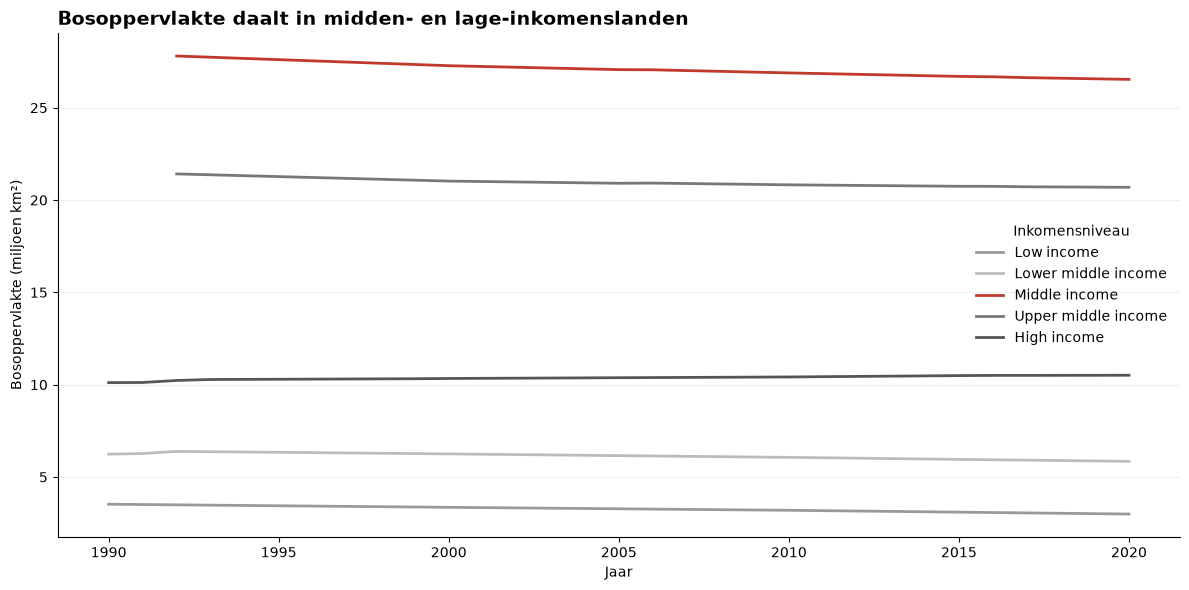

In [67]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=forest_b,
    x="year",
    y=forest_b["forest_area"] / 1000000,
    hue="area_name",
    hue_order=income_groups,
    palette=["#999999", "#BBBBBB", "#C0392B", "#777777", "#555555"],
    linewidth=2
)

plt.title(
    "Bosoppervlakte daalt in midden- en lage-inkomenslanden",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Jaar")
plt.ylabel("Bosoppervlakte (miljoen km²)")
plt.xticks(range(1990, 2021, 5))
plt.legend(title="Inkomensniveau", frameon=False)

plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek B

**Grafiekkeuze:** Ik heb gekozen voor een lijngrafiek omdat
je hiermee veranderingen over tijd goed kunt zien en de
verschillende inkomensgroepen kunt vergelijken.

**Context:** De bosoppervlakte in middeninkomenslanden is
tussen 1992 en 2020 met ongeveer 1,27 miljoen km² afgenomen.
VN-leiders kunnen deze informatie gebruiken om te bepalen
waar extra maatregelen tegen ontbossing nodig zijn.

**Clutter:** Ik heb onnodige randen en het kader rondom de
legenda verwijderd. De rasterlijnen zijn minder opvallend
en de bosoppervlakte wordt weergegeven in miljoenen km².
Hierdoor is de grafiek makkelijker te lezen.

**Preattentive attributes:** Ik heb Middle income rood
gemaakt en de overige lijnen grijs. Door het kleurcontrast
wordt de aandacht direct naar de belangrijkste trend geleid.

Voor Middle income en Upper middle income
ontbreken gegevens uit 1990 en 1991. Middle income omvat
ook Lower middle income en Upper middle income.

# Opdracht D – Bosoppervlakte in 2020

In [68]:
groups = [
    "World",
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_d = forest[forest["area_name"].isin(groups)]
forest_d = forest_d[forest_d["year"] == 2020]
forest_d = forest_d.sort_values("forest_area")

display(forest_d)

,area_name,area_code,year,forest_area
8225,Low income,LIC,2020,2991863.4
8226,Lower middle income,LMC,2020,5845811.0
8213,High income,HIC,2020,10510106.5
8244,Upper middle income,UMC,2020,20689597.8
8230,Middle income,MIC,2020,26535408.8
8245,World,WLD,2020,40499687.7


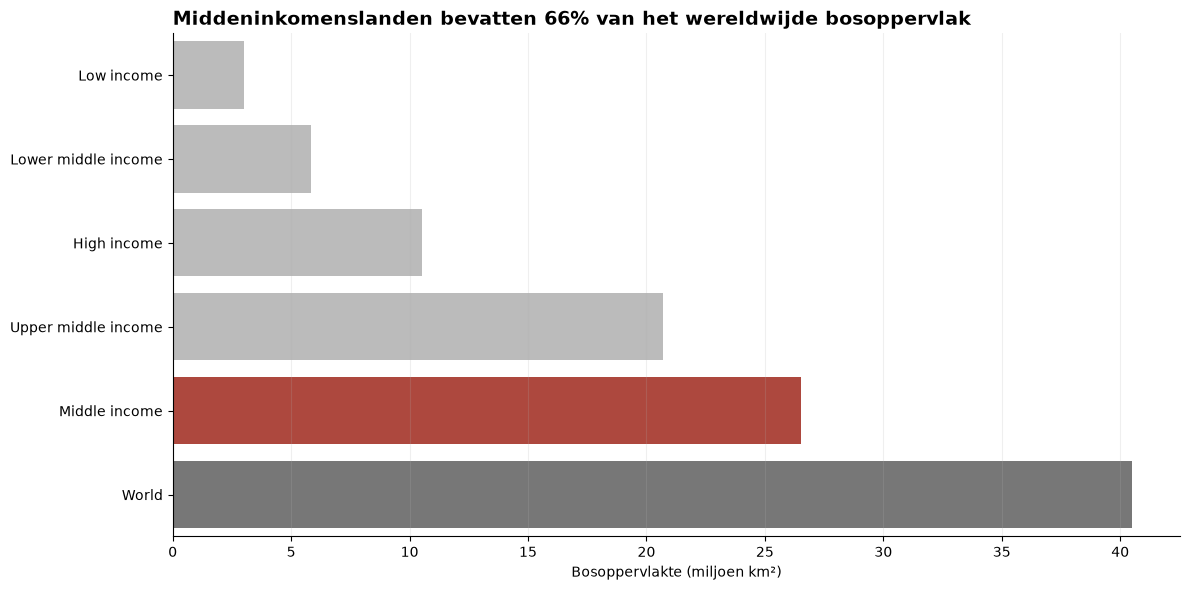

In [69]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=forest_d,
    x=forest_d["forest_area"] / 1000000,
    y="area_name",
    hue="area_name",
    palette=["#BBBBBB", "#BBBBBB", "#BBBBBB",
             "#BBBBBB", "#C0392B", "#777777"],
    legend=False
)

plt.title(
    "Middeninkomenslanden bevatten 66% van het wereldwijde bosoppervlak",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Bosoppervlakte (miljoen km²)")
plt.ylabel("")

plt.grid(axis="x", alpha=0.2)
sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek D

**Grafiekkeuze:** Ik heb gekozen voor een horizontaal
staafdiagram omdat je hiermee de bosoppervlakte van
verschillende inkomensgroepen in hetzelfde jaar goed
kunt vergelijken.

**Context:** In 2020 bevond ongeveer 66% van het
wereldwijde bosoppervlak zich in middeninkomenslanden.
Voor VN-leiders zijn deze landen daarom belangrijk
bij het opstellen van maatregelen voor bosbescherming.

**Clutter:** Ik heb onnodige randen, de legenda en het
label van de Y-as verwijderd. De rasterlijnen zijn
minder opvallend gemaakt om afleiding te verminderen.

**Preattentive attributes:** Ik heb de staaf van Middle
income rood gemaakt om hier de aandacht op te richten.
Daarnaast zijn de staven gesorteerd op grootte,
waardoor de verschillen direct zichtbaar zijn.

World is het wereldtotaal. Middle income
omvat ook Lower middle income en Upper middle income.
De categorieën mogen daarom niet worden opgeteld.

# Opdracht F – Maandelijkse temperaturen in Nederland

In [70]:
temperature = pd.read_csv("city_temperature_preprocessed.csv")

temperature_f = temperature[temperature["Country"] == "The Netherlands"]

display(temperature_f)

,Region,Country,City,Month,Day,Year,AvgTemperature
767088,Europe,The Netherlands,Amsterdam,1,1,1995,3.1
767089,Europe,The Netherlands,Amsterdam,1,2,1995,3.7
767090,Europe,The Netherlands,Amsterdam,1,3,1995,0.7
767091,Europe,The Netherlands,Amsterdam,1,4,1995,-1.6
767092,Europe,The Netherlands,Amsterdam,1,5,1995,-3.4
...,...,...,...,...,...,...,...
776185,Europe,The Netherlands,Amsterdam,12,27,2019,4.0
776186,Europe,The Netherlands,Amsterdam,12,28,2019,0.7
776187,Europe,The Netherlands,Amsterdam,12,29,2019,1.5
776188,Europe,The Netherlands,Amsterdam,12,30,2019,4.6


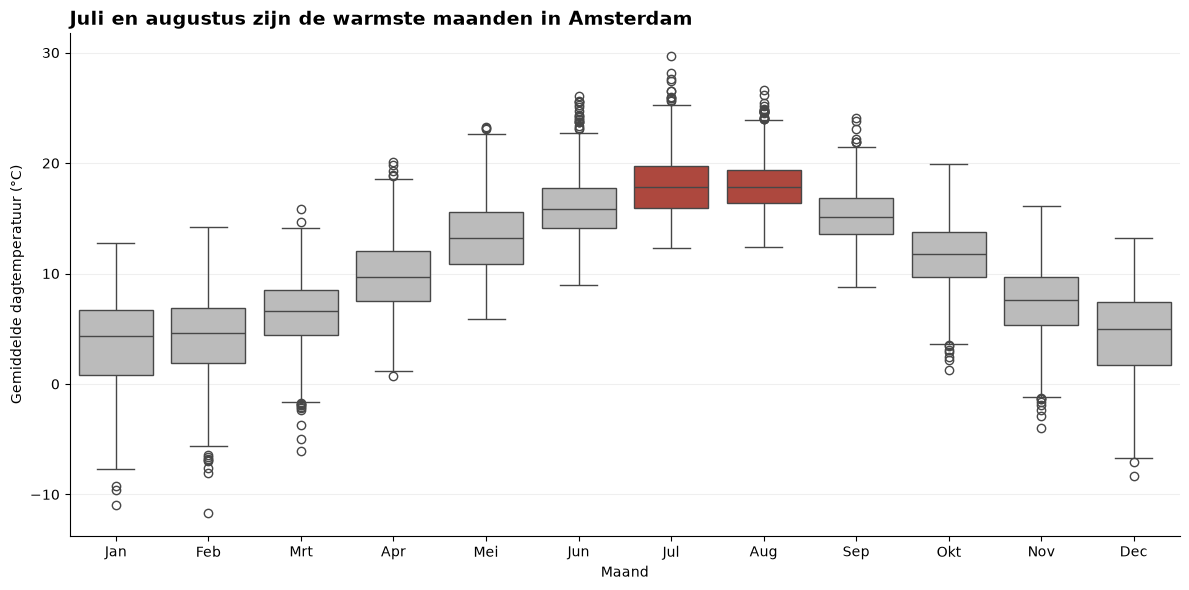

In [71]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=temperature_f,
    x="Month",
    y="AvgTemperature",
    hue="Month",
    palette=[
        "#BBBBBB", "#BBBBBB", "#BBBBBB",
        "#BBBBBB", "#BBBBBB", "#BBBBBB",
        "#C0392B", "#C0392B", "#BBBBBB",
        "#BBBBBB", "#BBBBBB", "#BBBBBB"
    ],
    legend=False
)

plt.title(
    "Juli en augustus zijn de warmste maanden in Amsterdam",
    fontsize=14,
    fontweight="bold",
    loc="left"
)

plt.xlabel("Maand")
plt.ylabel("Gemiddelde dagtemperatuur (°C)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mrt", "Apr", "Mei", "Jun",
     "Jul", "Aug", "Sep", "Okt", "Nov", "Dec"]
)

plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()

plt.show()

### Onderbouwing grafiek F

**Grafiekkeuze:** Ik heb gekozen voor boxplots omdat
je hiermee de mediaan, spreiding en uitschieters van
de temperaturen per maand goed kunt vergelijken.

**Context:** Uit de temperatuurgegevens van 1995 tot
en met 2019 blijkt dat juli en augustus de warmste
maanden zijn. Beide maanden hebben een mediane
dagtemperatuur van 17,8 °C.

**Clutter:** Ik heb onnodige randen en de legenda
verwijderd. Ook heb ik korte maandnamen gebruikt en
de rasterlijnen minder opvallend gemaakt.

**Preattentive attributes:** Ik heb juli en augustus
rood gemaakt en de overige maanden grijs. Hierdoor
wordt de aandacht direct naar de warmste maanden
geleid.

De Nederlandse temperatuurgegevens
in deze dataset zijn afkomstig uit Amsterdam.